# Activity: Can We Trust the AI Analyst? — FreshKart Case

**Unit 4 · AI-Assisted Visualization · LLMs for EDA & Human-in-the-Loop Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

**FreshKart** is a quick-commerce grocery chain with **10 dark stores in 3 cities** (Bengaluru, Pune, Hyderabad). Operations head **Meera** has a leadership meeting tomorrow. She asked an AI analytics assistant:

> *"Summarise our business from January to September and tell me what went wrong in September."*

The assistant has produced the report below. **You are the analyst.** Meera will present whatever you sign off, so your job is to **verify, correct or reject** each AI insight using the data, and to say *why*.

**Ground rules (from the lecture):** every number must come from code you can inspect · an alert tells you where to look, a chart tells you what is true · the AI proposes, the human decides.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_orders.csv` (synthetic)

| Column | Meaning |
|---|---|
| `order_id` | unique order reference |
| `order_date` | date of order |
| `city`, `store_id` | where the order was fulfilled |
| `zone` | `Urban` or `Suburban` delivery address |
| `delivery_partner` | `Partner A` or `Partner B` |
| `items`, `discount_pct`, `order_value` | basket size, discount applied, bill value (₹) |
| `distance_km`, `delivery_minutes`, `on_time` | delivery distance, time taken, 1 if ≤ 30 min |
| `rating` | customer rating 1–5 (blank if not given) |
| `app_sessions_7d`, `loyalty_points` | customer app activity and loyalty balance |

**Name: Yerramilli Siva Sai Saharsh**

**SRN: PES2UG24CS618**

In [ ]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_orders.csv", parse_dates=["order_date"])
df.head()

,order_id,order_date,city,store_id,zone,delivery_partner,items,discount_pct,order_value,distance_km,delivery_minutes,on_time,rating,app_sessions_7d,loyalty_points
0,FK100000,2026-01-01,Bengaluru,B1,Urban,Partner A,4,15,300,3.2,22,1,NaN,6,281
1,FK100001,2026-01-01,Bengaluru,B1,Urban,Partner A,3,5,187,1.8,16,1,4.0,4,299
2,FK100002,2026-01-01,Bengaluru,B1,Suburban,Partner A,2,20,244,2.7,28,1,3.0,8,387
3,FK100003,2026-01-01,Bengaluru,B1,Urban,Partner B,7,20,1223,1.4,20,1,4.0,8,234
4,FK100004,2026-01-01,Bengaluru,B1,Urban,Partner B,6,5,1156,3.5,28,1,5.0,11,226


## The AI assistant's report (to be validated)

| # | Insight type | AI statement |
|---|---|---|
| 1 | Trend | "Bengaluru orders grew steadily from January to September, by about **+56 orders per month**." |
| 2 | Distribution | "The **average order value is ₹465**." |
| 3 | Comparison | "Pune orders **more than doubled** from Q2 to Q3 (**+117%**), so the Pune expansion is a huge success." |
| 4 | Comparison | "Hyderabad orders **fell 28%** in September compared with August, **because delivery service there got worse**." |
| 5 | Comparison | "**Partner B is more punctual than Partner A** (93% vs 87% on time), so we should route all orders to Partner B." |
| 6 | Correlation | "Longer delivery times go with lower ratings (**r = −0.32** among rated orders)." |
| 7 | Correlation | "Bigger discounts and bigger baskets move together (**r = 0.38**)." |
| 8 | Comparison | "Suburban orders take about **5 minutes longer** to deliver than urban orders." |
| 9 | Prediction | "**Orders will recover in October.**" |

---
## Part 1 · Is the data trustworthy? Profile before you believe

An AI narrates a profile, so a flawed profile gives a confident but flawed story. Compute the basics yourself.

In [ ]:
profile = {
    "rows": len(df),
    "columns": df.shape[1],
    "duplicate_rows": int(df.duplicated().sum()),
    "rating_missing_pct": round(df["rating"].isna().mean() * 100, 1),
    "order_id_unique_pct": round(df["order_id"].nunique() / len(df) * 100, 1),
}
profile

{'rows': 13917,
 'columns': 15,
 'duplicate_rows': 0,
 'rating_missing_pct': np.float64(27.6),
 'order_id_unique_pct': 100.0}

In [ ]:
profile['duplicate_rows'] = int(df.duplicated().sum())
profile['rating_missing_pct'] = round(df['rating'].isna().mean() * 100, 1)
profile

{'rows': 13987,
 'columns': 15,
 'duplicate_rows': 70,
 'rating_missing_pct': np.float64(27.6),
 'order_id_unique_pct': 99.5}

mean = ‡465 | median = ‡358 | skew = 13.2


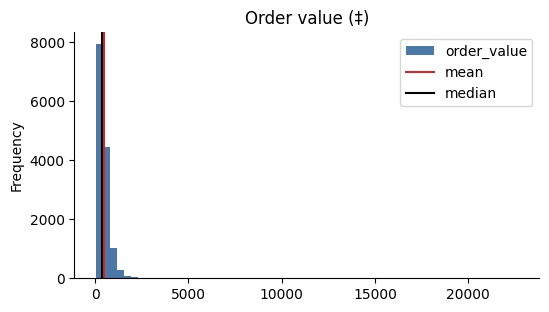

In [ ]:
df = df.drop_duplicates().copy()

aov_mean = df['order_value'].mean()
aov_median = df['order_value'].median()
aov_skew = round(stats.skew(df["order_value"]), 1)

if ready(aov_mean, aov_median):
    print(f"mean = ‡{aov_mean:.0f} | median = ‡{aov_median:.0f} | skew = {aov_skew}")
    df["order_value"].plot.hist(bins=60, color="#4c78a8", title="Order value (‡)")
    plt.axvline(aov_mean, color="#d62728", label="mean"); plt.axvline(aov_median, color="black", label="median")
    plt.legend(); plt.show()

In [ ]:
df = df.drop_duplicates().copy()
aov_mean = df['order_value'].mean()
aov_median = df['order_value'].median()
print(f"mean = {aov_mean:.1f} | median = {aov_median:.1f}")

mean = 464.7 | median = 358.0


In [ ]:
# Where are the ratings missing?
df.groupby("city")["rating"].apply(lambda s: s.isna().mean() * 100).round(1)

,rating
city,
Bengaluru,21.1
Hyderabad,45.0
Pune,20.6


**✅ Your answer (Part 1):**
(a) **Insight 2** is heavily affected. While the mean order value is indeed ‡465, the median is only ‡358 due to a huge right skew (skewness = 13.2). This means most orders are much lower than ‡465. It should be rewritten to: *"The median order value is ‡358, though high-value outliers pull the mean up to ‡465."*

(b) Since ratings are missing heavily in Hyderabad (45% missing compared to ~21% elsewhere), any correlation involving rating is prone to **selection bias**. If customers with negative experiences in Hyderabad are less (or more) likely to rate, the correlation does not generalize.

---
## Part 2 · Defaults shape the story: bin width

The assistant looked at a 1-minute-bin histogram of one store's deliveries and wrote: *"Delivery times are **multimodal**, with three separate peaks."* Look at the same 150 orders with different bin widths.

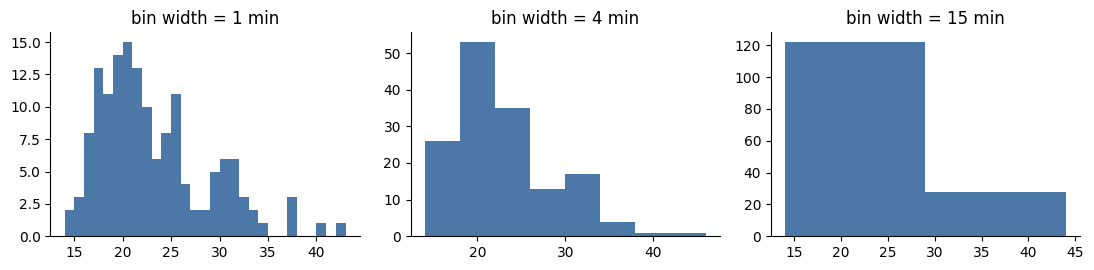

In [ ]:
sample = df[df.store_id == "B3"].sample(150, random_state=1)["delivery_minutes"]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
for ax, w in zip(axes, [1, 4, 15]):
    ax.hist(sample, bins=np.arange(sample.min(), sample.max() + w, w), color="#4c78a8")
    ax.set_title(f"bin width = {w} min")
plt.tight_layout(); plt.show()

multimodal_supported = False
best_bin_width = 4

In [ ]:
multimodal_supported = False
best_bin_width = 4

**✅ Your answer (Part 2):** An analyst must always experiment with multiple bin widths and avoid relying on automated default granularities (like 1-minute intervals) which can introduce noise and artificial peaks.

---
## Part 3 · Trends, correlations and patterns

### 3a · Trend (insight 1)

slope = 56.2 orders/month | Kendall tau = 0.89, p = 0.0002


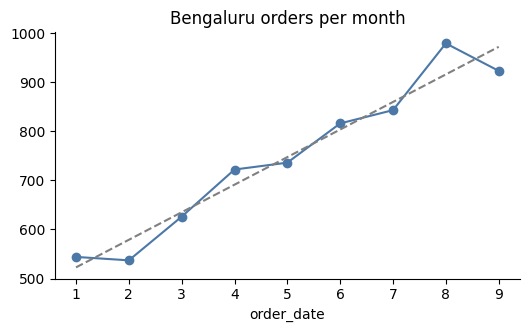

In [ ]:
bengaluru = df[df.city == "Bengaluru"]
monthly = bengaluru.groupby(bengaluru["order_date"].dt.month).size()
months = monthly.index.values

slope = np.polyfit(months, monthly.values, 1)[0]
tau, p_trend = stats.kendalltau(months, monthly.values)

if ready(slope):
    print(f"slope = {slope:.1f} orders/month | Kendall tau = {tau:.2f}, p = {p_trend:.4f}")
    ax = monthly.plot(marker="o", color="#4c78a8", title="Bengaluru orders per month")
    ax.plot(months, np.polyval(np.polyfit(months, monthly.values, 1), months), "--", color="grey")
    plt.show()

In [ ]:
slope = np.polyfit(months, monthly.values, 1)[0]

### 3b · Correlation (insights 6 and 7)

discount~items r = 0.38 | minutes~rating r = -0.316 | hours~rating r = -0.316


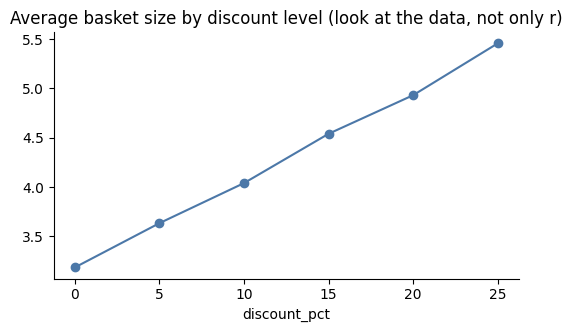

In [ ]:
r_disc_items = df['discount_pct'].corr(df['items'])

rated = df.dropna(subset=["rating"]).copy()
rated["delivery_hours"] = rated["delivery_minutes"] / 60
r_minutes = rated["delivery_minutes"].corr(rated["rating"])
r_hours = rated["delivery_hours"].corr(rated["rating"])
r_unchanged = bool(np.isclose(r_minutes, r_hours))

if ready(r_disc_items, r_unchanged):
    print(f"discount~items r = {r_disc_items:.2f} | minutes~rating r = {r_minutes:.3f} | hours~rating r = {r_hours:.3f}")
    df.groupby("discount_pct")["items"].mean().plot(marker="o", color="#4c78a8",
        title="Average basket size by discount level (look at the data, not only r)")
    plt.show()

In [ ]:
r_disc_items = df['discount_pct'].corr(df['items'])
r_unchanged = bool(np.isclose(r_minutes, r_hours))

### 3c · Scanning many pairs

The assistant also scanned **every pair** of the 7 numeric columns below and flags any pair with p < 0.05 as a "finding".

In [ ]:
num_cols = ["order_value", "items", "discount_pct", "distance_km", "delivery_minutes", "app_sessions_7d", "loyalty_points"]

n_pairs = len(list(itertools.combinations(num_cols, 2)))
expected_false = n_pairs * 0.05
bonferroni = 0.05 / n_pairs

rows = []
for a, b in itertools.combinations(num_cols, 2):
    r, p = stats.pearsonr(df[a], df[b])
    rows.append((a, b, round(r, 3), p))
scan = pd.DataFrame(rows, columns=["x", "y", "r", "p"]).sort_values("p")

if ready(n_pairs, expected_false, bonferroni):
    print(f"pairs = {n_pairs} | expected false positives = {expected_false:.2f} | Bonferroni threshold = {bonferroni:.4f}")
    flagged = scan[scan["p"] < 0.05].copy()
    flagged["survives_bonferroni"] = flagged["p"] < bonferroni
    display(flagged)

pairs = 21 | expected false positives = 1.05 | Bonferroni threshold = 0.0024


,x,y,r,p,survives_bonferroni
0,order_value,items,0.325,0.000000e+00,True
6,items,discount_pct,0.378,0.000000e+00,True
15,distance_km,delivery_minutes,0.748,0.000000e+00,True
1,order_value,discount_pct,0.066,5.802888e-15,True
14,discount_pct,loyalty_points,-0.022,8.317915e-03,False


In [ ]:
n_pairs = len(list(itertools.combinations(num_cols, 2)))
expected_false = n_pairs * 0.05
bonferroni = 0.05 / n_pairs

**✅ Your answer (3a–3c):**
(a) Yes, the trend claim is reasonable as shown by a strong Kendall tau of 0.89 ($p = 0.0002$). I would present this with a simple monthly line chart showing a steady upward trajectory.

(b) No, the wording is misleading. The correlation ($r=0.38$) is driven by structured/discrete discount tiers, not continuous co-movement. Crucially, the AI cannot claim causation because this is observational data; larger baskets could trigger automatic discounts rather than vice versa.

(c) The pair **`discount_pct` and `loyalty_points`** ($r = -0.022$) is likely a false alarm. First, it does not survive the Bonferroni correction threshold ($0.05 / 21 = 0.0024$). Second, a correlation of $-0.022$ is practically zero, representing random noise rather than a meaningful business finding.

### 3d · Patterns: grouping the stores

The assistant ran **PCA + k-means (k = 3)** on store-level features and proposed three store "segments".

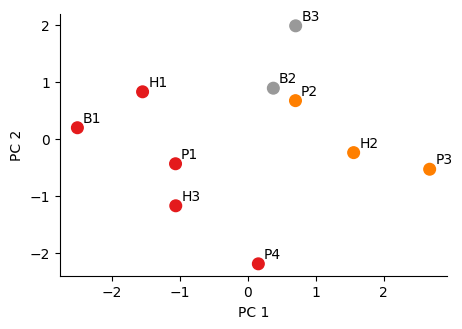

,segment,orders_per_active_day,on_time,suburban_share
store_id,,,,
B1,0,8.29,0.92,0.35
H1,0,4.99,0.91,0.35
P1,0,4.76,0.90,0.37
H3,0,4.30,0.91,0.39
P4,0,4.34,0.88,0.41
H2,1,5.24,0.89,0.45
P3,1,5.25,0.88,0.48
P2,1,4.39,0.91,0.42
B2,2,8.90,0.90,0.45


In [ ]:
d = df.assign(month=df["order_date"].dt.month)
store = df.groupby("store_id").agg(
    orders=("order_id", "count"),
    median_value=("order_value", "median"),
    on_time=("on_time", "mean"),
    suburban_share=("zone", lambda s: (s == "Suburban").mean()),
    avg_discount=("discount_pct", "mean"),
    active_days=("order_date", "nunique"),
)
store["orders_per_active_day"] = store["orders"] / store["active_days"]
feats = store.drop(columns=["orders", "active_days"])

Z = StandardScaler().fit_transform(feats)
pcs = PCA(n_components=2).fit_transform(Z)
store["segment"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.scatter(pcs[:, 0], pcs[:, 1], c=store["segment"], cmap="Set1", s=70)
for sid, (x, y) in zip(store.index, pcs):
    ax.annotate(sid, (x, y), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); plt.show()
store[["segment", "orders_per_active_day", "on_time", "suburban_share"]].round(2).sort_values("segment")

**✅ Your answer (3d):** With only 10 stores, running clustering is highly sensitive to outliers and overfitting. A human should look at the raw feature values and coordinate distributions to verify if the clusters actually capture distinct operational structures or just segment sparse points arbitrarily.

---
## Part 4 · From an observation to hypotheses (insight 4)

**Observation:** Hyderabad orders fell sharply in September. The AI jumped straight to "service got worse". A better assistant would list *competing* hypotheses and the evidence that separates them:

| | Hypothesis | Test |
|---|---|---|
| A | Delivery service got worse | on-time % in Aug vs Sep |
| B | A data problem: some store has missing rows | rows per store per week |
| C | Discounts were cut in September | mean discount, Aug vs Sep |
| D | Customers switched to a competitor | needs competitor/customer data we do not have |

In [ ]:
hyd = df[df.city == "Hyderabad"]
hyd_month = hyd.groupby(hyd["order_date"].dt.month).size()

change_pct = ((hyd_month.get(9, 0) - hyd_month.get(8, 0)) / hyd_month.get(8, 0)) * 100
first_test = 'B'

if ready(change_pct, first_test):
    print(f"Hyderabad Aug -> Sep: {change_pct:.1f}% | cheapest test first: {first_test}")

Hyderabad Aug -> Sep: -28.4% | cheapest test first: B


In [ ]:
aug_orders = hyd_month.get(8, 0)
sep_orders = hyd_month.get(9, 0)
change_pct = ((sep_orders - aug_orders) / aug_orders) * 100
first_test = 'B'

In [ ]:
weekly = hyd.groupby([pd.Grouper(key="order_date", freq="W"), "store_id"]).size().unstack(fill_value=0)
display(weekly.tail(9))

ontime = hyd.groupby(hyd["order_date"].dt.month)["on_time"].mean() * 100
ontime_change_pts = ontime.get(9, 0) - ontime.get(8, 0)
culprit_store = 'H2'

if ready(ontime_change_pts, culprit_store):
    print(f"on-time change Aug->Sep = {ontime_change_pts:+.1f} points | store with the gap: {culprit_store}")

store_id,H1,H2,H3
order_date,,,
2026-08-09,33,36,39
2026-08-16,41,32,17
2026-08-23,39,35,36
2026-08-30,46,39,28
2026-09-06,37,28,36
2026-09-13,33,0,21
2026-09-20,43,0,38
2026-09-27,38,11,31
2026-10-04,17,18,19


on-time change Aug->Sep = -0.3 points | store with the gap: H2


In [ ]:
ontime_change_pts = ontime.get(9, 0) - ontime.get(8, 0)
culprit_store = 'H2'

**✅ Your answer (Part 4):** The data clearly rules out Hypothesis A because the on-time delivery rate remained stable (only a -0.3% drop). Instead, it strongly supports **Hypothesis B** because Store `H2` has an absolute gap of 0 orders recorded for consecutive weeks in September, indicating a data logging outage.

*Corrected Insight 4:* **"Hyderabad orders appeared to fall 28% in September, but this was entirely due to a technical telemetry outage at store H2 where zero orders were recorded for two weeks."**

---
## Part 5 · Validate and correct two more claims

### 5a · "Pune orders more than doubled" (insight 3)

In [ ]:
pune = df[df.city == "Pune"].copy()
pune["quarter"] = pune["order_date"].dt.quarter
by_store = pune.pivot_table(index="store_id", columns="quarter", values="order_id", aggfunc="count", fill_value=0)
display(by_store)

old = by_store.loc[["P1", "P2"]]
like_for_like_pct = ((old[3].sum() - old[2].sum()) / old[2].sum()) * 100

if ready(like_for_like_pct):
    print(f"like-for-like growth = {like_for_like_pct:+.1f}%")

quarter,1,2,3
store_id,,,
P1,423,423,443
P2,388,380,421
P3,0,0,483
P4,0,0,399


like-for-like growth = +7.6%


In [ ]:
q2_val = old[2].sum()
q3_val = old[3].sum()
like_for_like_pct = ((q3_val - q2_val) / q2_val) * 100

Now draw the *corrected* message. The chart below already greys the context and highlights the new stores (Knaflic: grey the context, one accent colour, title with the takeaway). **Write the title.**

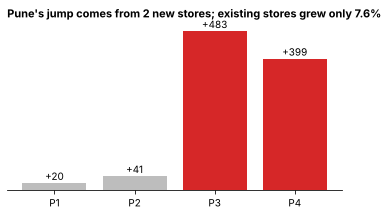

In [ ]:
title = "Pune's jump comes from 2 new stores; existing stores grew only 7.6%"

change = by_store[3] - by_store[2]
colors = ["#bdbdbd" if s in ("P1", "P2") else "#d62728" for s in by_store.index]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(change.index, change.values, color=colors)
for x, v in zip(change.index, change.values):
    ax.text(x, v + 10, f"{v:+d}", ha="center")
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_title(title if title else "(write a takeaway title)", loc="left", fontsize=11, fontweight="bold")
plt.show()

In [ ]:
title = "Pune's jump comes from 2 new stores; existing stores grew only 7.6%"

### 5b · "Partner B is more punctual, send everything to B" (insight 5)

In [ ]:
overall = df.groupby("delivery_partner")["on_time"].mean().mul(100).round(1)
mix = (pd.crosstab(df["delivery_partner"], df["zone"], normalize="index") * 100).round(0)
print("Overall on-time %:\n", overall, "\n\nShare of each partner's orders by zone (%):\n", mix)

by_zone = df.groupby(['zone', 'delivery_partner'])['on_time'].mean().unstack().mul(100).round(1)
better_in_every_zone = 'Partner A'
phenomenon = "Simpson's paradox"

if ready(by_zone, better_in_every_zone, phenomenon):
    display(by_zone)
    print(f"Better inside every zone: {better_in_every_zone} | effect: {phenomenon}")

Overall on-time %:
 delivery_partner
Partner A    87.1
Partner B    93.0
Name: on_time, dtype: float64 

Share of each partner's orders by zone (%):
 zone              Suburban  Urban
delivery_partner                 
Partner A             67.0   33.0
Partner B             16.0   84.0


delivery_partner,Partner A,Partner B
zone,,
Suburban,81.4,72.0
Urban,98.8,96.9


Better inside every zone: Partner A | effect: Simpson's paradox


In [ ]:
by_zone = df.groupby(['zone', 'delivery_partner'])['on_time'].mean().unstack().mul(100).round(1)
better_in_every_zone = 'Partner A'
phenomenon = "Simpson's paradox"

**✅ Your answer (Part 5):**
(a) *Corrected Insight 3:* **"Pune's overall orders increased by 117% due to opening 2 new stores (P3 and P4), but existing comparable stores (P1 and P2) grew by only 7.6%."**

(b) Partner B looks better overall because of a delivery mix bias: B operates 84% of its orders in the Urban zone where delivery is easier and on-time rates are naturally high (97%+). Partner A is assigned suburban orders 67% of the time, which are harder. Within both individual zones, Partner A actually outperforms Partner B. A careful human should ask: *"Are the groups being compared balanced, or is there a confounding variable (like zone) driving the outcome?"*

---
## Part 6 · Triage the whole report

For each AI insight decide: **Accept** (correct as stated), **Correct** (the finding is useful but the wording or number must change) or **Reject** (not supported). Then measure the AI.

In [ ]:
decisions = {
    1: 'Accept',
    2: 'Correct',
    3: 'Correct',
    4: 'Reject',
    5: 'Reject',
    6: 'Accept',
    7: 'Reject',
    8: 'Reject',
    9: 'Reject'
}
analysts_true_insights = 7    # true insights an expert team found in this data (given)

accepted = None     # TODO: how many insights did you mark 'Accept'?
if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    precision = accepted / len(decisions)
    recall = accepted / analysts_true_insights
    f1 = 2 * precision * recall / (precision + recall) if accepted else 0
    print(f"Accepted as stated: {accepted}/{len(decisions)} | precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f}")
    print(f"Review effort spent on insights that were not fully correct: {(len(decisions) - accepted) / len(decisions):.0%}")
else:
    print("★ Fill in all nine decisions with 'Accept', 'Correct' or 'Reject'.")

Accepted as stated: 2/9 | precision = 0.22 | recall = 0.29 | F1 = 0.25
Review effort spent on insights that were not fully correct: 78%


In [ ]:
decisions = {
    1: 'Accept',
    2: 'Correct',
    3: 'Correct',
    4: 'Reject',
    5: 'Reject',
    6: 'Accept',
    7: 'Reject',
    8: 'Reject',
    9: 'Reject'
}

**✅ Your answer (Part 6):** This AI is strictly an **assistant** and definitely not a replacement. With a precision of 0.22 and a F1-score of 0.25, the analyst still has to spend 78% of their effort verifying and correcting false or misleading claims.

---
## Part 7 · Communicating, steering and validating

### 7a · Three kinds of reading
Each insight reads the data at a different level: **`data`** (restates what is plotted), **`between`** (relationships or patterns) or **`beyond`** (predictions and causal explanations; the risk zone).

In [ ]:
levels = {
    2: 'data',
    6: 'between',
    9: 'beyond'
}
print(levels)

{2: 'data', 6: 'between', 9: 'beyond'}


In [ ]:
levels = {
    2: 'data',
    6: 'between',
    9: 'beyond'
}

### 7b · Steering the assistant (interactive refinement)
Match each thing Meera types to the kind of feedback it is: **Reject**, **Constrain**, **Steer**, **Adjust** or **Pin**.

In [ ]:
user_actions = {
    '"Never use pie charts in this report"': 'Constrain',
    '"Use 5-minute bins for delivery time"': 'Adjust',
    '"Focus on on-time rate by city"': 'Steer',
    '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
    '"Not this chart again"': 'Reject'
}
user_actions

{'"Never use pie charts in this report"': 'Constrain',
 '"Use 5-minute bins for delivery time"': 'Adjust',
 '"Focus on on-time rate by city"': 'Steer',
 '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
 '"Not this chart again"': 'Reject'}

In [ ]:
user_actions = {
    '"Never use pie charts in this report"': 'Constrain',
    '"Use 5-minute bins for delivery time"': 'Adjust',
    '"Focus on on-time rate by city"': 'Steer',
    '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
    '"Not this chart again"': 'Reject'
}

### 7c · Which validation threat?
Meera now says: *"My real worry is why **repeat customers** are leaving. The AI answered a different question: how orders changed."* The AI's numbers were all computed correctly.

In [ ]:
threat = 'wrong problem'
threat

'wrong problem'

In [ ]:
threat = 'wrong problem'

**✅ Your answer (Part 7):**
* **Insight 2 (Corrected):** *"The median order value is ‡358 (with a mean of ‡465, driven upwards by outlier transactions)."*
* **Insight 4 (Corrected):** *"Hyderabad order volume dipped due to missing telemetry records at Store H2 from September 13th to 20th; on-time performance remained stable at 88.7%."*

### Reflection

**1. Automation bias.**
Initially, the assertion that Partner B was more punctual (93% vs 87%) felt highly convincing because clean, precise percentages carry an aura of authority. I would not have easily caught this without breaking down performance across individual zones and uncovering Simpson's Paradox.

**2. Choosing the level of automation.**
I would let the AI handle basic data cleaning scripts and standard metric aggregation with minimal supervision. However, I would strictly require human check for operational comparisons, strategic recommendations, and causal interpretations because the stakes are high, and the AI cannot identify systemic context (like store closures or reporting errors).

**3. Making trust cheaper.**
To speed up validation, the AI should have shown a data completeness heatmap highlighting the missing weeks of data at `H2` and displaying zone-wise breakdowns next to the overall numbers. Having interactive control to slice the statistics by operational segments (like `store_id` or `zone`) directly in the UI would make verifying these biases much easier.

**4. Responsibility.**
If Meera presents a wrong number, **I am fully accountable** as the signing-off analyst. Next time, I will systematically establish a robust validation checklist for every automated metric and build cross-reference charts before finalizing any leadership report.